# 2C.2 Complexiteit

We hebben in de vorige notebook besproken dat bubble sort en merge sort niet even snel werken. Dit heeft te maken met het aantal berekeningen dat beide methodes gebruiken om hun eindresultaat te bereiken. Hoe hoger het aantal berekeningen nodig, hoe hoger de complexiteit van het algoritme. In de computerwetenschappen worden algoritmes daarom vaak ingedeeld naar gelang hun complexiteit in bepaalde klasses volgens de 'grote O' notatie. Deze wordt gebruikt om het 'worst case scenario', i.e., het maximum aantal bewerkingen die moeten uitgevoerd worden indien we pech hebben, uit te drukken. Die klasses zijn handig omdat algoritmes zo snel kunnen vergeleken worden en er bepaalde eigenschappen aan toegedicht kunnen worden. Dit is belangrijk in domeinen zoals artificiële intelligentie waarbij computers menselijke handelingen proberen na te bootsen zonder te veel rekenkracht te vergen, in beveiliging (denk aan het encrypteren, waar we net wel versleutelingen willen bouwen die zo veel mogelijk bewerkingen nodig hebben om met pure kracht te kraken), of in blockchain transacties (wederom het hashen van bepaalde transacties).

De volgende klasses worden dikwijls gebruikt voor een probleem met inputdimensie $n$ (bv. de lengte van een rij die te sorteren valt, etc.):
<table>
<thead>
  <tr>
    <th>Naam</th>
    <th>Grote-O-notatie</th>
    <th>Voorbeeld</th>
  </tr>
</thead>
<tbody>
  <tr>
    <td>Constant</td>
    <td>$O(1)$</td>
    <td>Neem eerste getal van rij</td>
  </tr>
  <tr>
    <td>Logaritmisch</td>
    <td>$O(log(n))$</td>
    <td>Zoek maximum in rij met recursie</td>
  </tr>
  <tr>
    <td>Lineair</td>
    <td>$O(n)$</td>
    <td>Zoek maximum in rij via lneair doorlopen</td>
  </tr>
  <tr>
    <td>Linearitmisch/loglineair</td>
    <td>$O(n log(n))$ of $O(n log_2(n))$</td>
    <td>Merge sort</td>
  </tr>
  <tr>
    <td>Kwadratisch</td>
    <td>$O(n^2)$</td>
    <td>Bubble sort</td>
  </tr>
  <tr>
    <td>Polynomiaal</td>
    <td>$2^{O(log(n))}$</td>
    <td>Lineair programeerprobleem</td>
  </tr>
  <tr>
    <td>Exponentieel</td>
    <td>$O(2^n)$</td>
    <td>Exacte oplossing handelsreizigersprobleem met enumeratie</td>
  </tr>
  <tr>
    <td>Factorieel</td>
    <td>$O(n!)$</td>
    <td>Opsommen van alle subsets van een set (complete enumeratie)</td>
  </tr>
</tbody>
</table>

Zoals eerder gezegd verschillende bubble sort en merge sort en dat valt hier te zien aan hun verschillende complexiteitsklasses.

Bubble sort:
- Slechts mogelijke complexiteit: $O(n^2)$ vergelijkingen en $O(n^2)$ keer verwisselen
- Kwadratisch want $2\times O(n^2)$ blijft complexiteit $O(n^2)$.

Merge sort:
- Slechts mogelijke complexiteit: $O(n log(n))$:
    - $n$: het samenvoegen van de lijsten
    - $log(n)$: het opdelen van de lijst en de recursieve opdeling
- Lineairitmisch.

Hier merken we dus dat het verdeel- en heersprincipe goed standhoudt en maakt dat het probleem naar $log(n)$ lijsten wordt vertaald in plaats van $n^2$ vergelijkingen.

## Empirische evaluatie

We zullen nu code-matig laten zien dat beide methodes inderdaad deze complexiteit zullen benaderen. We doen dit door de tijd te meten die nodig is om lijsten van verschillende groottes te sorteren. We doen dit ook een aantal keer om ervoor te zorgen dat onze enkele observatie voor een bepaalde lijstlengte geen toeval is.

Hier nemen we eerst even de code van de vorige notebook mee om de berekeningen te doen:

In [1]:
def merge(lijst1, lijst2):
    teller1 = 0
    teller2 = 0
    n1 = len(lijst1)
    n2 = len(lijst2)
    lijst_merge = []

    while (teller1 < n1) and (teller2 < n2):
        if lijst1[teller1] < lijst2[teller2]:
            lijst_merge.append(lijst1[teller1])
            teller1 += 1
        else:
            lijst_merge.append(lijst2[teller2])
            teller2 += 1
    while teller1 < n1:
        lijst_merge.append(lijst1[teller1])
        teller1 += 1
    while teller2 < n2:
        lijst_merge.append(lijst2[teller2])
        teller2 += 1
    return lijst_merge


def merge_sort(lijst):
    n = len(lijst)
    if n > 1:
        midden = n // 2
        lijstLinks = merge_sort(lijst[:midden])
        lijstRechts = merge_sort(lijst[midden:])
        return merge(lijstLinks, lijstRechts)
    else: 
        return lijst


def bubble_sort(reeks_in):
    verwisseld = True # begin vanuit de assumptie dat we moeten verwisselen
    aantal_rondes = 0

    while verwisseld:
        aantal_rondes += 1
        verwisseld = False # als de ronde begonnen is zetten we verwisseld op False tot het tegendeel bewezen is

        for positie in range(1, len(reeks_in)): # controleer vanaf het 2de element (op positie 1 dus)
            if reeks_in[positie] < reeks_in[positie-1]: # indien gewisseld moet worden
                getal = reeks_in[positie]
                reeks_in[positie] = reeks_in[positie-1]
                reeks_in[positie-1] = getal
                verwisseld = True # er is verwisseld, hierna volgt dus nog een ronde
    return reeks_in

Nu gaan we ons zelf experiment opzetten. We gebruiken een for-lus met verschillende lijst-lengtes (10-500 met stappen van 20 ertussen) en doen dit 100 keer per lijst-lengte. Zo zijn we zeker dat er niet toevallig heel makkelijke of heel moeilijke lijsten voorkwamen, maar we sorteren wel telkens dezelfde lijst met beide algoritmes. Met `time` meten we de begin- en eindtijd en houden deze bij in een reeks. Per lijst-lengte berekenen we de gemiddelde berekeningstijd met NumPy (zie later). Deze kunnen we hieronder dan plotten.

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

merge_sort_reeks = []
bubble_sort_reeks = []
for n in range(10, 500, 20):  # verschillende lijstlengtes
    print('n:', n)
    observaties_merge_sort = []
    observaties_bubble_sort = []

    for i in range(0, 100):  # 100 keer herhaald
        # een lijst tussen 1 en 100 van n lang
        lijst_1 = np.random.randint(1, 100, n)

        begin_tijd = time.time()
        merge_sort(lijst_1)
        eind_tijd = time.time()
        observaties_merge_sort.append(eind_tijd-begin_tijd)

        begin_tijd = time.time()
        bubble_sort(lijst_1)
        eind_tijd = time.time()
        observaties_bubble_sort.append(eind_tijd-begin_tijd)

    merge_sort_reeks.append(np.mean(observaties_merge_sort))
    bubble_sort_reeks.append(np.mean(observaties_bubble_sort))

n: 10
n: 30
n: 50
n: 70
n: 90
n: 110
n: 130
n: 150
n: 170
n: 190
n: 210
n: 230
n: 250
n: 270
n: 290
n: 310
n: 330
n: 350
n: 370
n: 390
n: 410
n: 430
n: 450
n: 470
n: 490


Een van de meest gebruikte visualisatiepakketten is matplotlib. We gebruiken het hieronder om een simpele grafiek te maken van de gemiddelde uitvoertijden met de lengte van de lijst op de x-as en de berekeningstijd op de y-as:

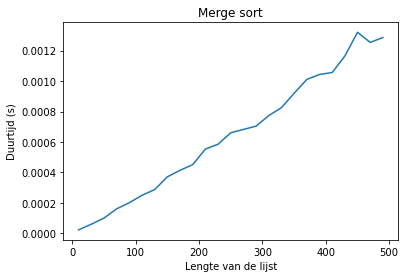

In [3]:
plt.plot(range(10, 500, 20), merge_sort_reeks)
plt.xlabel('Lengte van de lijst')
plt.ylabel('Duurtijd (s)')
plt.title('Merge sort')
plt.savefig('merge sort')
plt.show()

Het lijkt erop dat de uitvoertijd van merge sort min of meer een rechte lijn volgt en dus inderdaad lineaire tijd benadert.

Nu kijken we even naar bubble sort:

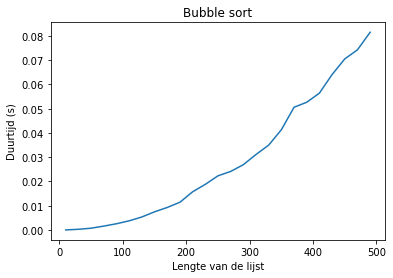

In [4]:
plt.plot(range(10, 500, 20), bubble_sort_reeks)
plt.xlabel('Lengte van de lijst')
plt.ylabel('Duurtijd (s)')
plt.title('Bubble sort')
plt.savefig('bubble sort')
plt.show()

Hier zien we dat bubble sort inderdaad de kwadratische curve begint te vormen. We zien ook dat de duurtijd veel hoger is op de y-as.